<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Student Performance Segmentation and Academic Success Profiling</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

In [1]:

# Import libraries for data handling
import pandas as pd
import numpy as np

# Import libraries for data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Import tools for data preprocessing and clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Import model evaluation metrics
from sklearn.metrics import silhouette_score, accuracy_score

# Import tools for model training and tuning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

print("All imports working")


All imports working


### Question 1: Data Ingestion and Structural Verification (4 Marks)

Load the StudentsPerformance.csv dataset from the verified URL: https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv. Read it into a pandas DataFrame named df. Verify the data ingestion by asserting that the DataFrame contains exactly 1000 rows and 8 columns. Display the deep memory usage and the first 3 rows of the dataset.

Hint: Use pd.read_csv() to load the data. You can verify the dimensions using the .shape attribute and display detailed memory usage with df.info(memory_usage='deep').

Expected Output: A summary of the DataFrame's memory allocation and a tabular preview displaying the first three records of the dataset.

In [2]:

# Load the student performance dataset from GitHub
url = "https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv"
df = pd.read_csv(url)

# Check whether the dataset contains 1000 rows and 8 columns
assert df.shape == (1000, 8), f"Unexpected shape: {df.shape}"

# Display dataset information, including memory usage
df.info(memory_usage='deep')

# Display the first 3 rows of the dataset
df.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 303.7 KB


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93


### Question 2: Data Standardization and Missing Value Strategy (5 Marks)

The dataset columns contain spaces and special characters. Rename the columns by replacing all spaces and slashes with underscores (e.g., 'math score' becomes 'math_score', 'race/ethnicity' becomes 'race_ethnicity'). Drop any duplicate rows. Print the sum of missing values for each column to verify data integrity. Finally, print a 1-2 sentence justification on why verifying and handling missing values early is critical for distance-based machine learning algorithms.

Hint: Use the df.rename() method with a lambda function or list comprehension. Check for nulls using df.isnull().sum(). Use print() for your written justification.

Expected Output: A printed series showing zero missing values for the standardized column names, followed by a printed analytical statement explaining the mathematical sensitivity of algorithms to null values.

In [3]:

# Replace spaces and slashes in column names with underscores
df.columns = df.columns.str.replace(' ', '_').str.replace('/', '_')

# Remove duplicate rows from the dataset
df = df.drop_duplicates()

# Check for missing values in each column
print(df.isnull().sum())

# Explain why missing values should be handled early
print(
    "Missing values should be handled before applying K-Means "
    "because K-Means cannot calculate distances when the "
    "input data contains missing values."
)


gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64
Missing values should be handled before applying K-Means because K-Means cannot calculate distances when the input data contains missing values.


### Question 3: Exploratory Data Analysis: Correlation Matrices (8 Marks)

Perform Exploratory Data Analysis (EDA) by calculating the Pearson correlation matrix for the numerical features (math_score, reading_score, writing_score). Visualize this matrix using a seaborn heatmap with annotations enabled. Print a written analysis identifying which two subjects exhibit the strongest correlation and hypothesize a brief academic reason why.

Hint: Isolate the numerical columns and use the .corr() method. Pass the resulting matrix to sns.heatmap(annot=True). Use print() to output your textual analysis.

Expected Output: A heatmap plot displaying a color gradient representative of correlation strength between the subjects, accompanied by a printed analytical conclusion.

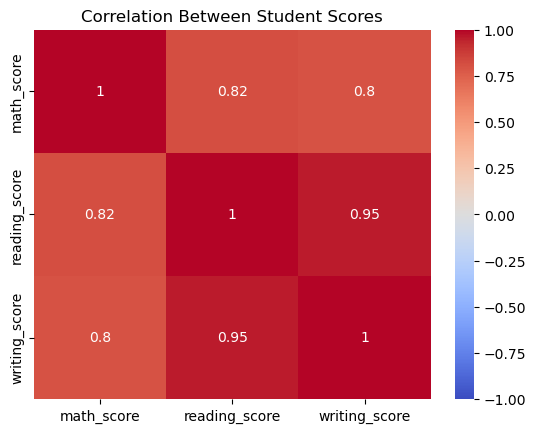

Reading and writing scores have the strongest positive correlation. This means students who score higher in reading also tend to score higher in writing. However, correlation does not prove causation.


In [4]:

# Calculate correlation between the three subject scores
corr = df[['math_score', 'reading_score', 'writing_score']].corr()

# Create a heatmap to visualize the correlations
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)

# Add a title to the heatmap
plt.title("Correlation Between Student Scores")
plt.show()

# Interpret the correlation results
print(
    "Reading and writing scores have the strongest positive "
    "correlation. This means students who score higher in "
    "reading also tend to score higher in writing. "
    "However, correlation does not prove causation."
)


### Question 4: Feature Engineering: Composite Performance (6 Marks)

Calculate an overall academic performance metric for the students rather than relying on isolated subject scores. Create a new numerical column named composite_score that represents the mean of math_score, reading_score, and writing_score for each row. Drop the three original subject score columns from the DataFrame.

Hint: Compute the mean across the horizontal axis (axis=1) for the specific score columns. Use df.drop(columns=[...]) to remove the redundant features.

Expected Output: A modified pandas DataFrame reflecting the updated schema where the three individual score columns are replaced by a single composite metric.

In [5]:

# Calculate the average score of each student across three subjects
df['composite_score'] = df[['math_score', 'reading_score', 'writing_score']].mean(axis=1)

# Remove the original subject score columns
df = df.drop(columns=['math_score', 'reading_score', 'writing_score'])

# Display the first 5 rows of the updated dataset
df.head()


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,composite_score
0,female,group B,bachelor's degree,standard,none,72.666667
1,female,group C,some college,standard,completed,82.333333
2,female,group B,master's degree,standard,none,92.666667
3,male,group A,associate's degree,free/reduced,none,49.333333
4,male,group C,some college,standard,none,76.333333


### Question 5: Categorical Encoding (6 Marks)

Convert the categorical variables (gender, race_ethnicity, parental_level_of_education, lunch, and test_preparation_course) into numerical format using one-hot encoding. Set drop_first=True to mitigate multicollinearity. Save this numerical dataset as a new DataFrame named df_encoded.

Hint: Utilize the pd.get_dummies() function on the categorical columns. Ensure boolean outputs are cast to integers (0s and 1s).

Expected Output: A widened DataFrame where the original text-based categorical columns are replaced by binary numerical indicators alongside the continuous composite_score.

In [6]:

# Select the categorical columns for encoding
cat_cols = ['gender', 'race_ethnicity', 'parental_level_of_education',
            'lunch', 'test_preparation_course']

# Convert categorical values into numerical dummy variables
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

# Display the first 5 rows of the encoded dataset
df_encoded.head()


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,72.666667,0,1,0,0,0,1,0,0,0,0,1,1
1,82.333333,0,0,1,0,0,0,0,0,1,0,1,0
2,92.666667,0,1,0,0,0,0,0,1,0,0,1,1
3,49.333333,1,0,0,0,0,0,0,0,0,0,0,1
4,76.333333,1,0,1,0,0,0,0,0,1,0,1,1


### Question 6: Feature Scaling and Dimensional Retention (6 Marks)

Distance-based algorithms require scaled features to prevent magnitude bias. Standardize all features in df_encoded so that they have a mean of 0 and a standard deviation of 1. Explicitly convert the resulting scaled NumPy array back into a pandas DataFrame named X_scaled, retaining the exact column names from df_encoded.

Hint: Apply the fit_transform method from sklearn's StandardScaler. Wrap the output using pd.DataFrame(), explicitly assigning the columns parameter to df_encoded.columns.

Expected Output: A standardized pandas DataFrame consisting entirely of scaled numerical values, with the original feature headers fully intact.

In [7]:

# Initialize StandardScaler for feature standardization
scaler = StandardScaler()

# Scale all features and convert the result into a DataFrame
X_scaled = pd.DataFrame(
    scaler.fit_transform(df_encoded),
    columns=df_encoded.columns
)

# Display the first 5 rows of the scaled dataset
X_scaled.head()


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,0.343574,-0.964625,2.064742,-0.684419,-0.59583,-0.403473,2.733967,-0.493742,-0.250398,-0.540361,-0.466933,0.741881,0.746748
1,1.021927,-0.964625,-0.484322,1.461094,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,0.741881,-1.339140
2,1.747064,-0.964625,2.064742,-0.684419,-0.59583,-0.403473,-0.365769,-0.493742,3.993639,-0.540361,-0.466933,0.741881,0.746748
3,-1.293830,1.036672,-0.484322,-0.684419,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,-0.540361,-0.466933,-1.347925,0.746748
4,0.600881,1.036672,-0.484322,1.461094,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,0.741881,0.746748


### Question 7: Cluster Optimization via Elbow Method (7 Marks)

Determine the optimal number of segments (k) for K-Means using the Elbow Method. Iterate k from 1 to 10. For each k, fit a KMeans model on X_scaled (setting random_state=42) and record the model's inertia. Plot these inertia values against the number of clusters using matplotlib.

Hint: Initialize an empty list. In a for loop, instantiate KMeans, fit the model to X_scaled, and append the .inertia_ attribute. Plot the resulting list as a line chart.

Expected Output: A line chart revealing a decreasing curve, allowing visual identification of the inflection point (elbow) for optimal cluster selection.

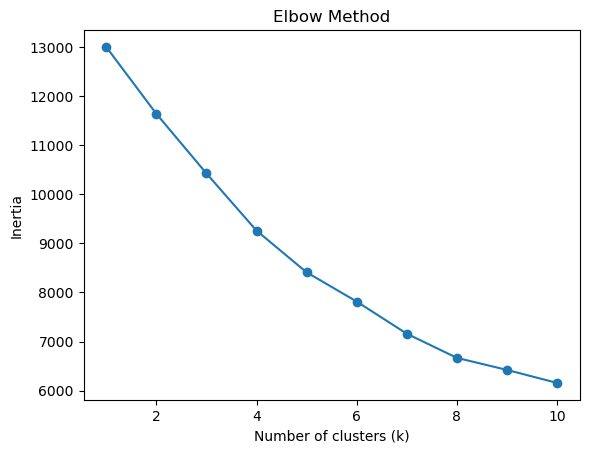

In [8]:

# Create an empty list to store inertia values
inertia_list = []

# Apply K-Means for different numbers of clusters (1 to 10)
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    # Store the inertia value for each k
    inertia_list.append(model.inertia_)

# Plot the Elbow Method graph
plt.plot(range(1, 11), inertia_list, marker='o')

# Add labels and title
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')

# Display the graph
plt.show()


### Question 8: K-Means Implementation and Silhouette Validation (7 Marks)

Assume the optimal number of clusters is 4. Instantiate a KMeans model with n_clusters=4 and random_state=42. Fit the model on X_scaled and extract the cluster assignments. Append these assignments as a new column named cluster_label in the original, unscaled df_encoded DataFrame. Calculate and print the Silhouette Score to mathematically validate the cluster cohesion.

Hint: Extract assignments using the .labels_ attribute. Import silhouette_score from sklearn.metrics, passing X_scaled and the predicted labels to compute the metric.

Expected Output: The unscaled DataFrame updated with integer cluster assignments, and a printed floating-point metric quantifying the density and separation of the segments.

In [9]:

# Initialize K-Means with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# Fit K-Means on the scaled dataset
kmeans.fit(X_scaled)

# Assign cluster labels to each student
df_encoded['cluster_label'] = kmeans.labels_

# Calculate the Silhouette Score to evaluate clustering quality
score = silhouette_score(X_scaled, kmeans.labels_)
print("Silhouette Score:", score)

# Display the first 5 rows with cluster labels
df_encoded.head()


Silhouette Score: 0.19538045595031325


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none,cluster_label
0,72.666667,0,1,0,0,0,1,0,0,0,0,1,1,3
1,82.333333,0,0,1,0,0,0,0,0,1,0,1,0,0
2,92.666667,0,1,0,0,0,0,0,1,0,0,1,1,3
3,49.333333,1,0,0,0,0,0,0,0,0,0,0,1,0
4,76.333333,1,0,1,0,0,0,0,0,1,0,1,1,0


### Question 9: Cluster Profiling and Interpretation (8 Marks)

Analyze the defining characteristics of each cluster. Group the df_encoded DataFrame by the cluster_label column and calculate the mean for all features. Display the aggregated table. Below the table, print a written analysis detailing the specific demographic and preparation traits that distinguish the cluster with the highest average composite score.

Hint: Utilize .groupby('cluster_label').mean(). Observe the binary categorical flags in the row corresponding to the highest composite_score to formulate your written response.

Expected Output: A statistical summary table with 4 rows representing the cluster centroids, followed by a printed conceptual assessment of the highest-performing student segment.

In [10]:

# Calculate the average values for each cluster
cluster_summary = df_encoded.groupby('cluster_label').mean()

# Display the cluster summary table
display(cluster_summary)

# Identify the cluster with the highest average composite score
highest_cluster = cluster_summary['composite_score'].idxmax()
highest_score = cluster_summary.loc[highest_cluster, 'composite_score']

# Select students from the highest-performing cluster
top_cluster = df_encoded[df_encoded['cluster_label'] == highest_cluster]

# Calculate percentages for the selected cluster
standard_lunch = top_cluster['lunch_standard'].mean() * 100
test_prep = (1 - top_cluster['test_preparation_course_none'].mean()) * 100

# Find the largest parental education category
education_cols = [
    col for col in df_encoded.columns
    if col.startswith('parental_level_of_education_')
]

education_percentages = top_cluster[education_cols].mean() * 100

# Calculate the percentage of the dropped reference category
education_percentages['associate\'s degree'] = (
    100 - education_percentages.sum()
)

largest_education = education_percentages.idxmax()
largest_education_percent = education_percentages.max()

# Calculate the percentage of students in race/ethnicity group E
group_e = top_cluster['race_ethnicity_group E'].mean() * 100

# Display the cluster interpretation
print(
    f"Cluster {highest_cluster} has the highest average "
    f"composite score ({highest_score:.1f}). "
    f"{group_e:.1f}% of students belong to race/ethnicity "
    f"group E. About {standard_lunch:.1f}% receive standard "
    f"lunch, and {test_prep:.1f}% completed the test "
    f"preparation course. The largest parental education "
    f"category is {largest_education.replace('parental_level_of_education_', '')}, "
    f"representing {largest_education_percent:.1f}% of this cluster."
)


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
cluster_label,,,,,,,,,,,,,
0,66.228758,0.470588,0.0,0.781863,0.0,0.0,0.127451,0.200980,0.053922,0.213235,0.178922,0.632353,0.637255
1,69.179389,0.507634,0.0,0.000000,1.0,0.0,0.106870,0.167939,0.087786,0.255725,0.190840,0.637405,0.687023
2,72.752381,0.507143,0.0,0.000000,0.0,1.0,0.128571,0.157143,0.057143,0.250000,0.128571,0.707143,0.571429
3,65.468421,0.452632,1.0,0.000000,0.0,0.0,0.105263,0.252632,0.031579,0.194737,0.200000,0.636842,0.642105


Cluster 2 has the highest average composite score (72.8). 100.0% of students belong to race/ethnicity group E. About 70.7% receive standard lunch, and 42.9% completed the test preparation course. The largest parental education category is associate's degree, representing 27.9% of this cluster.


### Question 10: Target Formulation and Class Imbalance Assessment (6 Marks)

Formulate a supervised learning task to predict a student's cluster segment based purely on their demographic and preparation variables. Define y as the cluster_label. Define your feature matrix X by dropping both composite_score and cluster_label from the X_scaled DataFrame to prevent data leakage. Check the class distribution of y. Print a brief analysis discussing whether class imbalance exists and how it might impact evaluation metrics.

Hint: Use .value_counts() on y. Consider whether accuracy remains a reliable metric when the distribution of classes is uneven.

Expected Output: A frequency count of the target classes and a printed analytical reasoning paragraph regarding class imbalance.

In [11]:

# Select cluster labels as the target variable
y = df_encoded['cluster_label']

# Select input features, excluding the composite score
X = X_scaled.drop(columns=['composite_score'])

# Display the number of students in each cluster
print("Students in each cluster:")
print(y.value_counts().sort_index())

# Calculate the percentage of students in each cluster
print("\nCluster percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

# Identify the largest and smallest clusters
cluster_counts = y.value_counts()
largest_cluster = cluster_counts.idxmax()
smallest_cluster = cluster_counts.idxmin()

# Explain the class distribution
print(
    f"\nCluster {largest_cluster} is the largest cluster with "
    f"{cluster_counts.max()} students "
    f"({cluster_counts.max() / len(y) * 100:.1f}%), "
    f"while Cluster {smallest_cluster} is the smallest with "
    f"{cluster_counts.min()} students "
    f"({cluster_counts.min() / len(y) * 100:.1f}%)."
)

print(
    "If the cluster sizes are unequal, accuracy alone can be "
    "misleading because a model may perform well on larger "
    "clusters but poorly on smaller ones. Therefore, "
    "precision, recall, and F1-score per class are also useful."
)


Students in each cluster:
cluster_label
0    408
1    262
2    140
3    190
Name: count, dtype: int64

Cluster percentages:
cluster_label
0    40.8
1    26.2
2    14.0
3    19.0
Name: proportion, dtype: float64

Cluster 0 is the largest cluster with 408 students (40.8%), while Cluster 2 is the smallest with 140 students (14.0%).
If the cluster sizes are unequal, accuracy alone can be misleading because a model may perform well on larger clusters but poorly on smaller ones. Therefore, precision, recall, and F1-score per class are also useful.


### Question 11: Baseline Classification and Cross-Validation (8 Marks)

Split X and y into 80% training and 20% testing sets, stratifying by y to maintain class distribution. Establish a baseline by training a Logistic Regression model on the training set. Evaluate the baseline model's robustness by performing 5-fold cross-validation on the training data. Print the mean cross-validation accuracy.

Hint: Import train_test_split, LogisticRegression, and cross_val_score. Compute the mean of the array returned by the cross-validation function.

Expected Output: A printed floating-point value representing the average cross-validated accuracy of the baseline model.

In [12]:

# Split the dataset into 80% training and 20% testing
# Stratify maintains the cluster proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Initialize the Logistic Regression model
baseline = LogisticRegression(max_iter=1000)

# Train the model using the training dataset
baseline.fit(X_train, y_train)

# Perform 5-fold cross-validation on the training data
cv_scores = cross_val_score(
    baseline, X_train, y_train, cv=5
)

# Display the mean cross-validation accuracy
print("Mean cross-validation accuracy:", cv_scores.mean())


Mean cross-validation accuracy: 1.0


### Question 12: Hyperparameter Tuning via GridSearchCV (9 Marks)

Implement Hyperparameter Tuning to optimize a RandomForestClassifier. Use GridSearchCV with a 3-fold cross-validation strategy. Define a parameter grid varying n_estimators (e.g., [50, 100, 200]) and max_depth (e.g., [None, 5, 10]). Fit the grid search on the training data and print the best hyperparameter configuration found.

Hint: Pass the model, parameter dictionary, and cv=3 to GridSearchCV. Extract the optimal configuration using the .best_params_ attribute after fitting.

Expected Output: A printed dictionary displaying the optimal hyperparameter values discovered during the exhaustive search.

In [13]:

# Define the hyperparameter values to test
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10]
}

# Initialize Random Forest and perform 3-fold GridSearchCV
grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3
)

# Train the models and find the best hyperparameters
grid.fit(X_train, y_train)

# Display the best hyperparameter combination
print("Best Parameters:", grid.best_params_)


Best Parameters: {'max_depth': None, 'n_estimators': 50}


### Question 13: Multi-Layer Perceptron (MLP) Classifier (8 Marks)

Define and train a deep learning architecture using scikit-learn. Instantiate an MLPClassifier with a single hidden layer of 32 units, ReLU activation, a maximum of 500 iterations, and random_state=42. Train the model on the training data.

Hint: Import MLPClassifier from sklearn.neural_network. Set hidden_layer_sizes=(32,). Use the .fit() method on your training sets.

Expected Output: A successfully initialized and trained MLP architecture, natively handling the multi-class prediction task.

In [14]:

# Initialize the MLP Classifier with one hidden layer of 32 neurons
mlp = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation='relu',
    max_iter=500,
    random_state=42
)

# Train the MLP model using the training dataset
mlp.fit(X_train, y_train)

# Display a message after training
print("MLP trained")


MLP trained


### Question 14: Comparative Model Evaluation (6 Marks)

Comprehensively evaluate all three trained models (Baseline Logistic Regression, Tuned Random Forest, and MLP Classifier) on the unseen testing set (X_test, y_test). Calculate and print the test accuracy for each model. Print a brief analytical comparison stating which algorithm generalized best and why you suspect it outperformed the others.

Hint: Generate test predictions using .predict() for each model. Import accuracy_score from sklearn.metrics. Use print() statements for the numerical results and your comparative reasoning.

Expected Output: Three printed accuracy scores followed by a short textual assessment of the comparative algorithm performance.

In [15]:

# Get the best Random Forest model from GridSearchCV
rf = grid.best_estimator_

# Calculate test accuracy for all three models
lr_accuracy = accuracy_score(y_test, baseline.predict(X_test))
rf_accuracy = accuracy_score(y_test, rf.predict(X_test))
mlp_accuracy = accuracy_score(y_test, mlp.predict(X_test))

# Display the accuracy scores
print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"MLP Classifier Accuracy: {mlp_accuracy:.4f}")

# Store model accuracies for comparison
model_scores = {
    'Logistic Regression': lr_accuracy,
    'Random Forest': rf_accuracy,
    'MLP Classifier': mlp_accuracy
}

# Identify the best-performing model
best_accuracy = max(model_scores.values())
best_models = [
    name for name, accuracy in model_scores.items()
    if accuracy == best_accuracy
]

# Display the model comparison
if len(best_models) == 1:
    print(f"\nBest Model: {best_models[0]}")
else:
    print(f"\nModels tied for best accuracy: {', '.join(best_models)}")

print(
    f"Highest test accuracy: {best_accuracy * 100:.2f}%. "
    "The models are predicting K-Means-generated cluster "
    "labels rather than independently measured academic "
    "success. Therefore, high accuracy should be interpreted "
    "cautiously. If models have equal accuracy, the simpler "
    "Logistic Regression model may be preferred."
)


Logistic Regression Accuracy: 1.0000
Random Forest Accuracy: 1.0000
MLP Classifier Accuracy: 1.0000

Models tied for best accuracy: Logistic Regression, Random Forest, MLP Classifier
Highest test accuracy: 100.00%. The models are predicting K-Means-generated cluster labels rather than independently measured academic success. Therefore, high accuracy should be interpreted cautiously. If models have equal accuracy, the simpler Logistic Regression model may be preferred.


### Question 15: Analytical Reasoning and Strategic Implementation (6 Marks)

Based on your modeling pipeline, formulate a concise 3-4 sentence business strategy explaining how an EdTech platform can utilize these predictive segments for targeted interventions. Store the response in a string variable named business_strategy and print it.

Hint: Consider how predicting a student's performance segment purely from demographic data and test preparation status upon enrollment can trigger early academic support or customized curriculum recommendations.

Expected Output: A structured paragraph printed to the screen containing actionable, domain-specific recommendations for an EdTech organization.

In [16]:

# Suggest a business strategy based on student segmentation
business_strategy = (
    "An EdTech platform can use this model to group new students into "
    "performance-related segments using their background information "
    "and test preparation status. "
    "Students assigned to historically lower-scoring segments can be "
    "offered additional tutoring, revision materials, and academic support. "
    "Test preparation courses can be recommended to segments where fewer "
    "students have completed them. "
    "These segments can help personalize learning, but individual academic "
    "needs should also be assessed before making recommendations."
)

# Display the proposed business strategy
print(business_strategy)


An EdTech platform can use this model to group new students into performance-related segments using their background information and test preparation status. Students assigned to historically lower-scoring segments can be offered additional tutoring, revision materials, and academic support. Test preparation courses can be recommended to segments where fewer students have completed them. These segments can help personalize learning, but individual academic needs should also be assessed before making recommendations.
